<a href="https://colab.research.google.com/github/kashvi613/MovieRecommendationSystem/blob/main/MovieRecommendationSystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-25m.zip
!unzip -q ml-25m.zip
!ls ml-25m

N
genome-scores.csv  links.csv   ratings.csv  tags.csv
genome-tags.csv    movies.csv  README.txt


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!unzip -q "/content/drive/MyDrive/MovieRec/ml-25m.zip" -d /content/
!ls /content/ml-25m

replace /content/ml-25m/tags.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
genome-scores.csv  links.csv   ratings.csv  tags.csv
genome-tags.csv    movies.csv  README.txt


In [5]:
import pandas as pd
import numpy as np

ratings = pd.read_csv(
    '/content/ml-25m/ratings.csv',
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}
)
movies = pd.read_csv('/content/ml-25m/movies.csv')

print("ratings:", ratings.shape)
print("movies:", movies.shape)
ratings.head()

ratings: (25000095, 4)
movies: (62423, 3)


,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510


In [6]:
print("Users:", ratings['userId'].nunique())
print("Movies rated:", ratings['movieId'].nunique())
print("Rating range:", ratings['rating'].min(), "to", ratings['rating'].max())

Users: 162541
Movies rated: 59047
Rating range: 0.5 to 5.0


In [31]:
movie_counts = ratings['movieId'].value_counts()
df = ratings[ratings['movieId'].isin(movie_counts[movie_counts >= 100].index)]

user_counts = df['userId'].value_counts()
good_users = user_counts[user_counts >= 50].index
df = df[df['userId'].isin(good_users)]

sampled_users = pd.Series(good_users).sample(n=15000, random_state=42)
df = df[df['userId'].isin(sampled_users)].copy()

movie_counts = df['movieId'].value_counts()
df = df[df['movieId'].isin(movie_counts[movie_counts >= 20].index)].copy()

df = df.reset_index(drop=True)
print(df.shape)

(3303977, 4)


In [8]:
print("Rows:", len(df))
print("Users:", df['userId'].nunique())
print("Movies:", df['movieId'].nunique())
print("Sparsity: {:.2f}%".format(100 * (1 - len(df) / (df['userId'].nunique() * df['movieId'].nunique()))))
print("Min ratings per user:", df['userId'].value_counts().min())
print("Min ratings per movie:", df['movieId'].value_counts().min())

Rows: 3303977
Users: 15000
Movies: 9155
Sparsity: 97.59%
Min ratings per user: 47
Min ratings per movie: 20


In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (user, movie) pairs:", df.duplicated(subset=['userId', 'movieId']).sum())

Duplicate rows: 0
Duplicate (user, movie) pairs: 0


In [10]:
print(df.isnull().sum())
print(movies.isnull().sum())

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
movieId    0
title      0
genres     0
dtype: int64


In [11]:
df['date'] = pd.to_datetime(df['timestamp'], unit='s')
df['rating_year'] = df['date'].dt.year
df[['userId', 'movieId', 'rating', 'date', 'rating_year']].head()

,userId,movieId,rating,date,rating_year
0,8,1,4.0,1998-03-21 15:01:57,1998
1,8,3,4.0,1998-03-21 15:08:26,1998
2,8,6,3.0,1998-03-21 14:15:13,1998
3,8,7,1.0,1998-03-21 15:00:14,1998
4,8,10,4.0,1998-03-21 14:22:49,1998


In [12]:
movies_small = movies[movies['movieId'].isin(df['movieId'].unique())].copy()
print(movies_small.shape)

(9155, 3)


In [13]:
movies_small['year'] = movies_small['title'].str.extract(r'\((\d{4})\)\s*$').astype('float')
print("Missing year:", movies_small['year'].isnull().sum())
movies_small['clean_title'] = movies_small['title'].str.replace(r'\s*\(\d{4}\)\s*$', '', regex=True)
movies_small.head()

Missing year: 12


,movieId,title,genres,year,clean_title
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,Toy Story
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0,Jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0,Grumpier Old Men
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,Waiting to Exhale
4,5,Father of the Bride Part II (1995),Comedy,1995.0,Father of the Bride Part II


In [14]:
movies_small['year'] = movies_small['year'].fillna(movies_small['year'].median())

In [15]:
movies_small['genres_list'] = movies_small['genres'].str.split('|')
movies_small['genres_list'] = movies_small['genres_list'].apply(
    lambda g: [] if g == ['(no genres listed)'] else g
)
movies_small[['clean_title', 'year', 'genres_list']].head()

,clean_title,year,genres_list
0,Toy Story,1995.0,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,Jumanji,1995.0,"[Adventure, Children, Fantasy]"
2,Grumpier Old Men,1995.0,"[Comedy, Romance]"
3,Waiting to Exhale,1995.0,"[Comedy, Drama, Romance]"
4,Father of the Bride Part II,1995.0,[Comedy]


In [16]:
data = df.merge(movies_small[['movieId', 'clean_title', 'year', 'genres_list']], on='movieId', how='left')
print(data.shape)
data.head()

(3303977, 9)


,userId,movieId,rating,timestamp,date,rating_year,clean_title,year,genres_list
0,8,1,4.0,890492517,1998-03-21 15:01:57,1998,Toy Story,1995.0,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,8,3,4.0,890492906,1998-03-21 15:08:26,1998,Grumpier Old Men,1995.0,"[Comedy, Romance]"
2,8,6,3.0,890489713,1998-03-21 14:15:13,1998,Heat,1995.0,"[Action, Crime, Thriller]"
3,8,7,1.0,890492414,1998-03-21 15:00:14,1998,Sabrina,1995.0,"[Comedy, Romance]"
4,8,10,4.0,890490169,1998-03-21 14:22:49,1998,GoldenEye,1995.0,"[Action, Adventure, Thriller]"


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
sns.set_style('whitegrid')

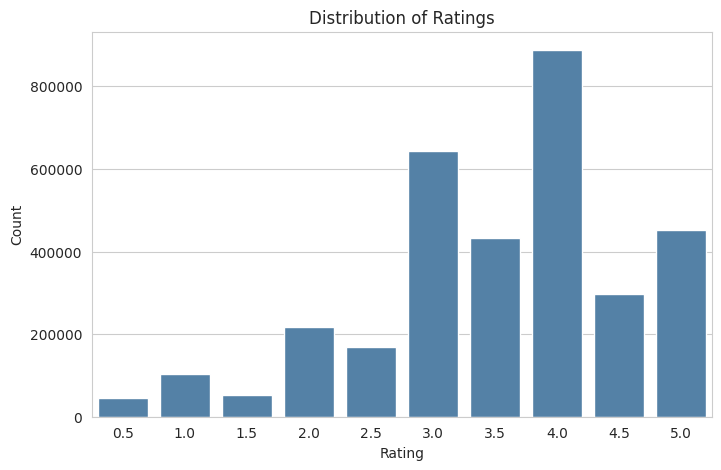

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(data=data, x='rating', color='steelblue')
plt.title('Distribution of Ratings')
plt.xlabel('Rating'); plt.ylabel('Count')
plt.show()

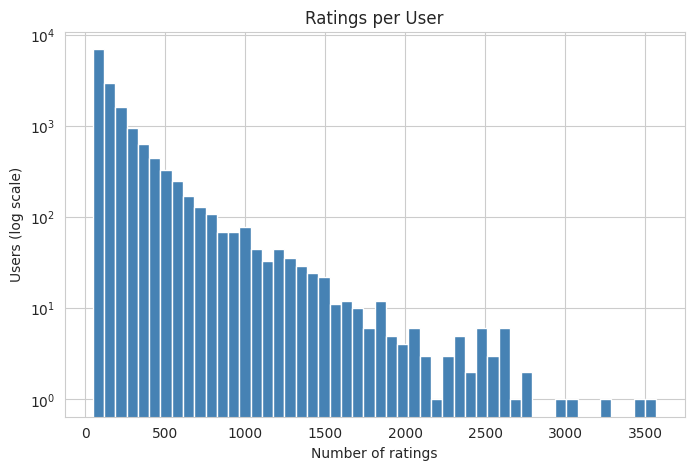

count    15000.000000
mean       220.265133
std        267.631377
min         47.000000
25%         77.000000
50%        128.000000
75%        245.000000
max       3572.000000
Name: count, dtype: float64


In [19]:
user_counts = data['userId'].value_counts()
plt.figure(figsize=(8,5))
plt.hist(user_counts, bins=50, color='steelblue', edgecolor='white')
plt.yscale('log')
plt.title('Ratings per User')
plt.xlabel('Number of ratings'); plt.ylabel('Users (log scale)')
plt.show()
print(user_counts.describe())

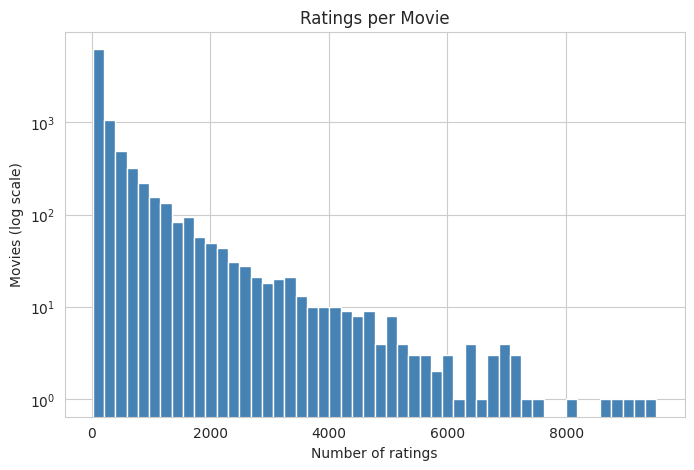

In [20]:
movie_counts = data['movieId'].value_counts()
plt.figure(figsize=(8,5))
plt.hist(movie_counts, bins=50, color='steelblue', edgecolor='white')
plt.yscale('log')
plt.title('Ratings per Movie')
plt.xlabel('Number of ratings'); plt.ylabel('Movies (log scale)')
plt.show()

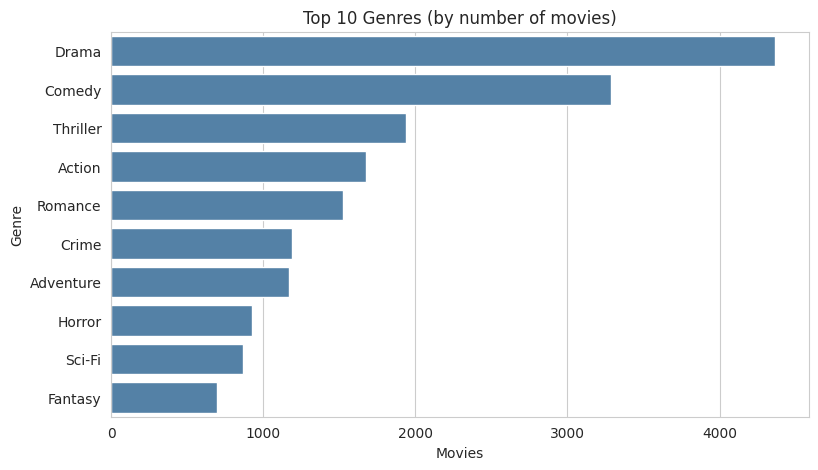

In [21]:
genre_counts = Counter(g for lst in movies_small['genres_list'] for g in lst)
top = pd.DataFrame(genre_counts.most_common(10), columns=['Genre', 'Movies'])
plt.figure(figsize=(9,5))
sns.barplot(data=top, x='Movies', y='Genre', color='steelblue')
plt.title('Top 10 Genres (by number of movies)')
plt.show()

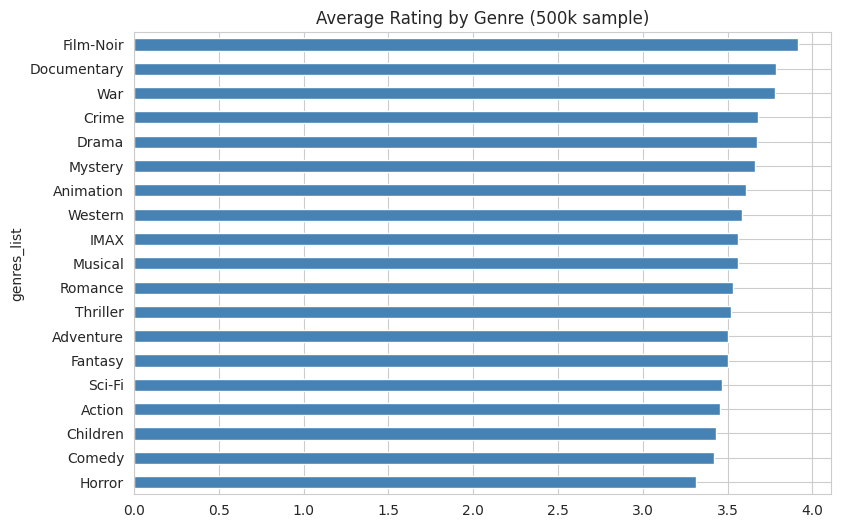

In [22]:
sample = data.sample(500000, random_state=42)
exploded = sample[['rating', 'genres_list']].explode('genres_list').dropna()
avg = exploded.groupby('genres_list')['rating'].mean().sort_values()
avg.plot(kind='barh', color='steelblue', figsize=(9,6))
plt.title('Average Rating by Genre (500k sample)'); plt.show()

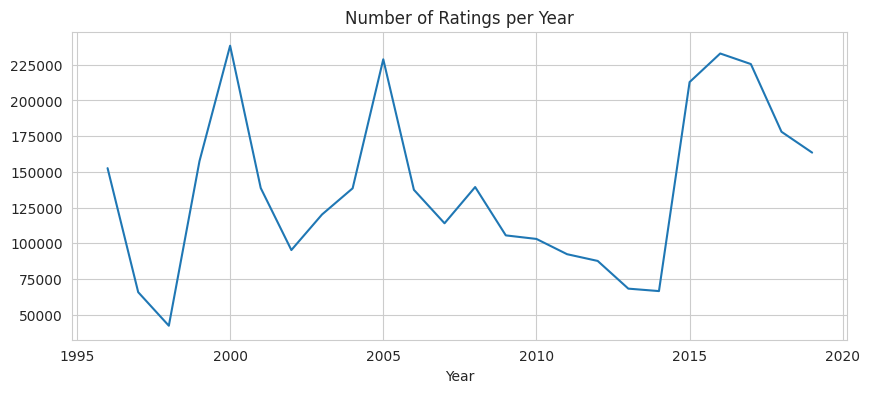

In [23]:
data['rating_year'].value_counts().sort_index().plot(kind='line', figsize=(10,4))
plt.title('Number of Ratings per Year'); plt.xlabel('Year'); plt.show()

In [24]:
data = data.sort_values(['userId', 'timestamp']).reset_index(drop=True)

pos = data.groupby('userId').cumcount()
n = data.groupby('userId')['userId'].transform('count')
data['pos_pct'] = pos / n

train = data[data['pos_pct'] < 0.8].copy()
test = data[data['pos_pct'] >= 0.8].copy()

print("Train:", train.shape, "Test:", test.shape)
print("Users in test but not in train:", len(set(test['userId']) - set(train['userId'])))

Train: (2649083, 10) Test: (654894, 10)
Users in test but not in train: 0


In [25]:
data = data.sort_values(['userId', 'timestamp']).reset_index(drop=True)

pos = data.groupby('userId').cumcount()
n = data.groupby('userId')['userId'].transform('count')
data['pos_pct'] = pos / n

train = data[data['pos_pct'] < 0.8].copy()
test = data[data['pos_pct'] >= 0.8].copy()

print("Train:", train.shape, "Test:", test.shape)
print("Users in test but not in train:", len(set(test['userId']) - set(train['userId'])))

Train: (2649083, 10) Test: (654894, 10)
Users in test but not in train: 0


In [26]:
global_mean = train['rating'].mean()

user_stats = train.groupby('userId')['rating'].agg(user_avg='mean', user_cnt='count').reset_index()
movie_stats = train.groupby('movieId')['rating'].agg(movie_avg='mean', movie_cnt='count').reset_index()

def add_features(d):
    d = d.merge(user_stats, on='userId', how='left').merge(movie_stats, on='movieId', how='left')
    d['movie_avg'] = d['movie_avg'].fillna(global_mean)
    d['movie_cnt'] = d['movie_cnt'].fillna(0)
    return d

train = add_features(train)
test = add_features(test)
print(test[['user_avg', 'user_cnt', 'movie_avg', 'movie_cnt']].isnull().sum())

user_avg     0
user_cnt     0
movie_avg    0
movie_cnt    0
dtype: int64


In [27]:
print("Train:", train.shape, "Test:", test.shape)
print("Users in test but not in train:", len(set(test['userId']) - set(train['userId'])))
train[['userId','movieId','rating','user_avg','user_cnt','movie_avg','movie_cnt']].head()

Train: (2649083, 14) Test: (654894, 14)
Users in test but not in train: 0


,userId,movieId,rating,user_avg,user_cnt,movie_avg,movie_cnt
0,8,1617,5.0,3.637097,124,4.066972,3270
1,8,1672,4.0,3.637097,124,3.636569,443
2,8,1777,3.0,3.637097,124,3.402317,1597
3,8,1704,4.0,3.637097,124,4.060136,4548
4,8,1721,4.0,3.637097,124,3.357208,4363


In [28]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
mlb.fit(movies_small['genres_list'])
genre_cols = ['g_' + c for c in mlb.classes_]

def add_genres(d):
    g = pd.DataFrame(mlb.transform(d['genres_list']), columns=genre_cols, index=d.index).astype('int8')
    return pd.concat([d, g], axis=1)

train = add_genres(train)
test = add_genres(test)
print(train.shape, test.shape)

(2649083, 33) (654894, 33)


In [29]:
from sklearn.preprocessing import StandardScaler

num_cols = ['user_avg', 'user_cnt', 'movie_avg', 'movie_cnt', 'year']
feature_cols = num_cols + genre_cols

X_train, y_train = train[feature_cols].copy(), train['rating']
X_test, y_test = test[feature_cols].copy(), test['rating']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train.shape, X_test.shape)

(2649083, 24) (654894, 24)


In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, y_true, pred):
    mse = mean_squared_error(y_true, pred)
    return [name, mean_absolute_error(y_true, pred), mse, np.sqrt(mse), r2_score(y_true, pred)]

results = []
base_pred = np.full(len(y_test), y_train.mean())
results.append(evaluate('Baseline (global mean)', y_test, base_pred))

lr = LinearRegression()
lr.fit(X_train, y_train)
results.append(evaluate('Linear Regression', y_test, lr.predict(X_test)))

pd.DataFrame(results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])

,Model,MAE,MSE,RMSE,R2
0,Baseline (global mean),0.816685,1.091663,1.044827,-0.008290
1,Linear Regression,0.662442,0.761523,0.872653,0.296636


In [33]:
from sklearn.ensemble import RandomForestRegressor

idx = X_train.sample(300000, random_state=42).index
rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=20, n_jobs=-1, random_state=42)
rf.fit(X_train.loc[idx], y_train.loc[idx])
results.append(evaluate('Random Forest (300k sample)', y_test, rf.predict(X_test)))

pd.DataFrame(results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])

,Model,MAE,MSE,RMSE,R2
0,Baseline (global mean),0.816685,1.091663,1.044827,-0.008290
1,Linear Regression,0.662442,0.761523,0.872653,0.296636
2,Random Forest (300k sample),0.658878,0.757811,0.870523,0.300065


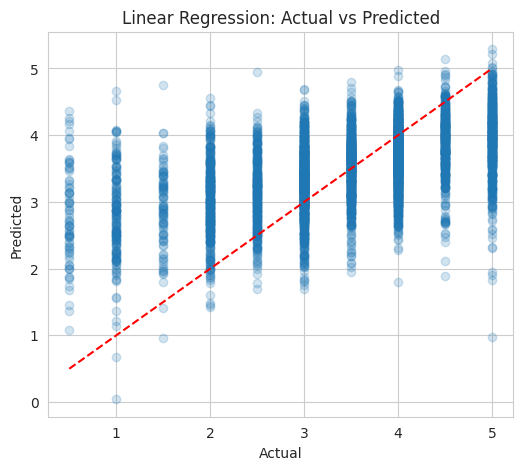

In [34]:
pred = lr.predict(X_test)
plt.figure(figsize=(6,5))
plt.scatter(y_test.sample(5000, random_state=1), pd.Series(pred, index=y_test.index).loc[y_test.sample(5000, random_state=1).index], alpha=0.2)
plt.plot([0.5,5],[0.5,5],'r--')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Linear Regression: Actual vs Predicted')
plt.show()

In [35]:
y_train_c = (y_train >= 4).astype(int)
y_test_c = (y_test >= 4).astype(int)
print("Liked share (train):", y_train_c.mean().round(3), " (test):", y_test_c.mean().round(3))

Liked share (train): 0.505  (test): 0.459


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

idx = X_train.sample(300000, random_state=42).index
Xs, ys = X_train.loc[idx], y_train_c.loc[idx]

clfs = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42),
    'Naive Bayes': GaussianNB(),
}

cres = []
for name, m in clfs.items():
    m.fit(Xs, ys)
    p = m.predict(X_test)
    cres.append([name, accuracy_score(y_test_c, p), precision_score(y_test_c, p),
                 recall_score(y_test_c, p), f1_score(y_test_c, p)])

pd.DataFrame(cres, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.702411,0.668374,0.698592,0.683149
1,Decision Tree,0.700704,0.667571,0.693691,0.680380
2,Random Forest,0.703282,0.672541,0.689664,0.680995
3,Naive Bayes,0.658279,0.664378,0.517084,0.581550


In [37]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1).fit(Xs.sample(50000, random_state=1), ys.loc[Xs.sample(50000, random_state=1).index])
ti = X_test.sample(20000, random_state=1).index
p = knn.predict(X_test.loc[ti])
print("KNN (50k train / 20k test) F1:", f1_score(y_test_c.loc[ti], p), "Acc:", accuracy_score(y_test_c.loc[ti], p))

KNN (50k train / 20k test) F1: 0.662369749704587 Acc: 0.6857


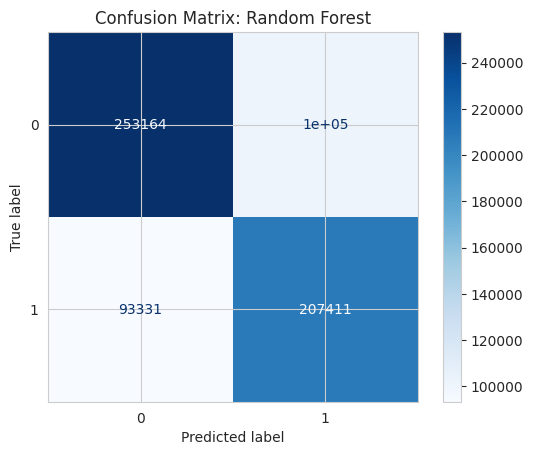

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
best = clfs['Random Forest']
ConfusionMatrixDisplay.from_predictions(y_test_c, best.predict(X_test), cmap='Blues')
plt.title('Confusion Matrix: Random Forest'); plt.show()